# 03 - Model Training and Comparison
### ActivitySense AI | Yash Rajput - 2427010652

Three classifiers - **KNN**, **SVM (RBF)**, **Random Forest** - tuned with GridSearchCV on the
training partition (scalers live inside pipelines to avoid leakage) and evaluated on the official
test set. Models are loaded here from the saved artifacts.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.data_loader import load_test
from src.predict import load_model, load_metadata
from src import config as C, visualize as V
from src.evaluate import classification_metrics
import time

Xte, yte, yte_name, _ = load_test()
meta = load_metadata()
full = meta["feature_cols_full"]

## Full-feature results on the official test set

In [3]:
rows = []
for name in C.MODEL_NAMES:
    model = load_model(name)
    t0 = time.perf_counter(); yp = model.predict(Xte[full]); pt = time.perf_counter() - t0
    r = classification_metrics(yte_name, yp); r["model"] = name
    r["predict_time_s"] = round(pt, 3)
    rows.append(r)
pd.DataFrame(rows)[["model", "accuracy", "macro_f1", "weighted_f1", "predict_time_s"]].round(3)

  File "C:\Users\Dell\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Dell\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dell\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dell\anaconda3\Lib\subprocess.py",

,model,accuracy,macro_f1,weighted_f1,predict_time_s
0,knn,0.888,0.885,0.887,0.428
1,svm,0.954,0.953,0.954,2.111
2,random_forest,0.926,0.924,0.926,0.135


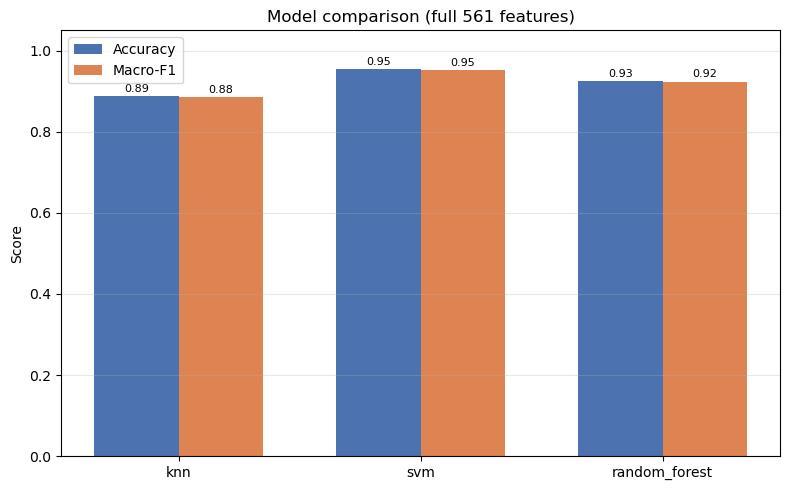

In [4]:
m = pd.read_csv(C.RESULTS_DIR / "metrics.csv")
V.plot_model_comparison(m[m.feature_group == "full"], C.FIGURES_DIR / "model_comparison.png")
plt.show()

**Observations (RQ1).** SVM gives the best accuracy, Random Forest is close, and KNN is behind.
On computational cost the picture flips: KNN trains almost instantly but is **slow at prediction**
(it compares each test point to all training points), while Random Forest predicts fastest. SVM is
a good balance of accuracy and speed here.